# A test of quantum data encoding and decoding

_This notebook explores data encoding and measurement in **PennyLane and PyTorch**_.

**By:** Jacob Cybulski ([website](https://jacobcybulski.com/))<br>
**Date:** October 1, 2024<br>
**Updated:** October 1, 2026<br>
**Aims:** To test data encoding and measurements in PennyLane<br/>
**Prerequisites:** We will assume your knowledge of *quantum computing*, *machine learning* and *Python*<br>
**License:** 
This project is licensed under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt)<br>
**Changes:** All changes to this code must be listed at the bottom of this notebook

In [4]:
import sys
sys.path.append('.')
sys.path.append('..')
sys.path

['c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\python312.zip',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\DLLs',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312',
 '',
 'C:\\Users\\codeg\\AppData\\Roaming\\Python\\Python312\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32\\lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\pythonwin',
 '.',
 '..']

In [5]:
import numpy as np
import sys
import json
import math
from utilities import *

np.set_printoptions(legacy='1.25') # for older version use 1.21

## Converting circuit probability distributilon to qubit conditional probability

In [6]:
probs1 = [0.1, 0.05, 0.05, 0.3, 0.2, 0.1, 0.2, 0.0]
probs2 = [0.01, 0.02, 0.3, 0, 0.03, 0, 0.1, 0, 0.04, 0, 0.05, 0.05, 0.1, 0.2, 0.02, 0.08]

### Takes a list of probabilities (add to 1) and presents them in tabular form
def report_c2p(probs, prec=10):
    digs = int(np.log2(len(probs)))
    ppairs = [(list(bin_int_to_list(p, digs)), np.round(probs[p], prec)) for p in range(len(probs))]
    return ppairs # [(list(qn), p) for qn, p in zip(qa, probs)]

### Converts results of circuit state_vector probability measurements 
#   to individual qubit conditional probabilities
#   probs: a list of circuit measurement probabilities (must be of length 2^n)
#   returns: all qubit conditional probabilities onto |0>
def cprobs_to_qprobs(probs):
    digs = int(np.log2(len(probs)))
    ppairs = [(bin_int_to_list(p, digs), probs[p]) for p in range(len(probs))]
    cond_probs = np.array([np.sum([pp[1] for pp in ppairs if pp[0][d] == 0]) for d in range(digs)])
    return cond_probs

res = cprobs_to_qprobs(probs2)
print('Result of mapping a circuit state to\nindividual qubit states:\n\n\t', np.round(res, 4), '\n')

report_c2p(probs2)

Result of mapping a circuit state to
individual qubit states:

	 [0.46 0.47 0.4  0.65] 



[([0, 0, 0, 0], 0.01),
 ([0, 0, 0, 1], 0.02),
 ([0, 0, 1, 0], 0.3),
 ([0, 0, 1, 1], 0),
 ([0, 1, 0, 0], 0.03),
 ([0, 1, 0, 1], 0),
 ([0, 1, 1, 0], 0.1),
 ([0, 1, 1, 1], 0),
 ([1, 0, 0, 0], 0.04),
 ([1, 0, 0, 1], 0),
 ([1, 0, 1, 0], 0.05),
 ([1, 0, 1, 1], 0.05),
 ([1, 1, 0, 0], 0.1),
 ([1, 1, 0, 1], 0.2),
 ([1, 1, 1, 0], 0.02),
 ([1, 1, 1, 1], 0.08)]

## Quantum encoding

### Amplitude embedding / encoding
Angles relative to $\vert 0 \rangle$

In [7]:
import pennylane as qml
import pennylane.numpy as np

dev = qml.device('default.qubit', wires=3)

@qml.qnode(dev)
def circuit(f=None):
    qml.AmplitudeEmbedding(features=f, wires=dev.wires, normalize=True, pad_with=0)
    return qml.expval(qml.Z(0)), qml.state()

In [8]:
vect = [0.1, -0.3, 0.5, 0.4, 0.2]
print(f'\nVector:\t\t{vect}')

norm = np.linalg.norm(vect)
norm_vect = np.round([i / norm for i in vect], 4)
print(f'Norm vector:\t{norm_vect}\n')

res, state = circuit(f=norm_vect)


Vector:		[0.1, -0.3, 0.5, 0.4, 0.2]
Norm vector:	[ 0.1348 -0.4045  0.6742  0.5394  0.2697]



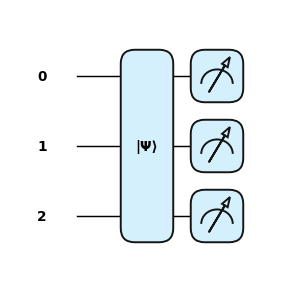

In [9]:
draw_circuit(circuit, level='device', scale=0.7)(f=norm_vect)

In [10]:
### Measurement results
res

0.8545278030287532

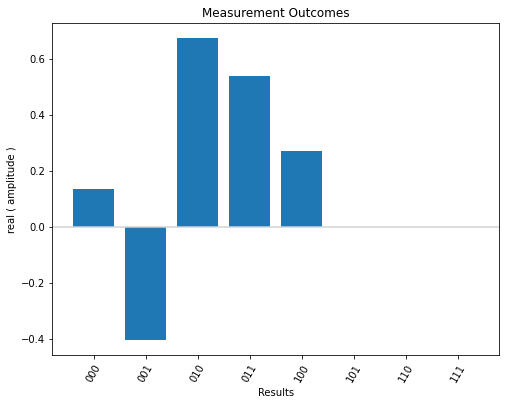

In [11]:
### Plots the real components of the circuit complete state
plot_hist(state.real, ylabel='real ( amplitude )', th=-1)

### Basis embedding / encoding

#### Measuring circuit state

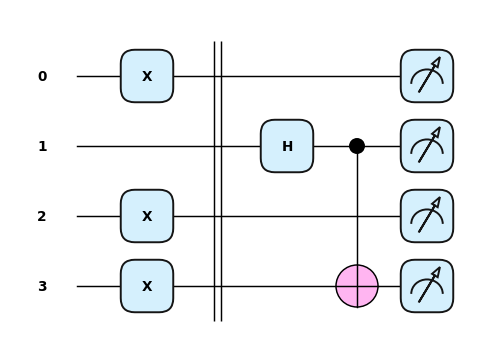

In [12]:
n_wires = 4
dev = qml.device('default.qubit', wires=n_wires)

@qml.qnode(dev)
def basis_circuit_1(features):
    # qml.BasisEmbedding(features=features, wires=range(len(feature_vector)))
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    qml.Barrier()
    qml.Hadamard(1)
    qml.CNOT([1, 3])
    return qml.state()

X = [1, 0, 1, 1]

draw_circuit(basis_circuit_1, level='user', scale=0.7)(X)


 [0.        +0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.70710678+0.j
 0.        +0.j 0.        +0.j 0.70710678+0.j 0.        +0.j] 



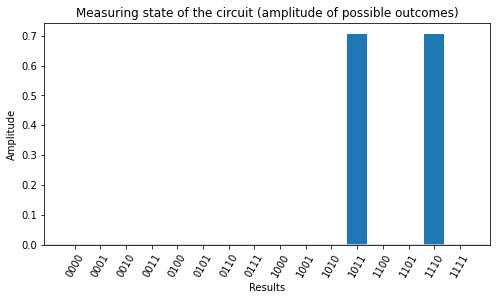

In [13]:
state = basis_circuit_1(X)
print('\n', state, '\n')
plot_hist(state.real, figsize=(8, 4), ylabel='Amplitude', title='Measuring state of the circuit (amplitude of possible outcomes)')

#### Measuring expectation

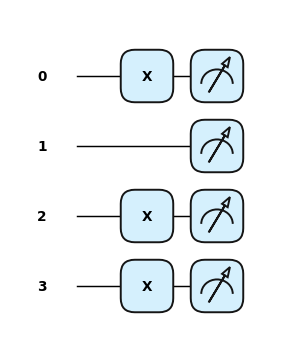

In [14]:
@qml.qnode(dev)
def basis_circuit_2A(features):
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    return [qml.expval(qml.PauliZ(m)) for m in range(len(features))]

X = [1, 0, 1, 1]

draw_circuit(basis_circuit_2A, level='device', scale=0.7)(X)


Expectation values: [-1.  1. -1. -1.]



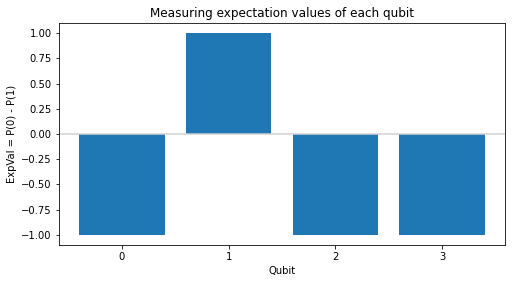

In [15]:
expvals = basis_circuit_2A(X)
print(f'\nExpectation values: {np.array(expvals)}\n')
plot_hist(expvals, figsize=(8, 4), ylabel='ExpVal = P(0) - P(1)', xlabel='Qubit',
          title='Measuring expectation values of each qubit',
          labels=[str(i) for i in range(len(X))])

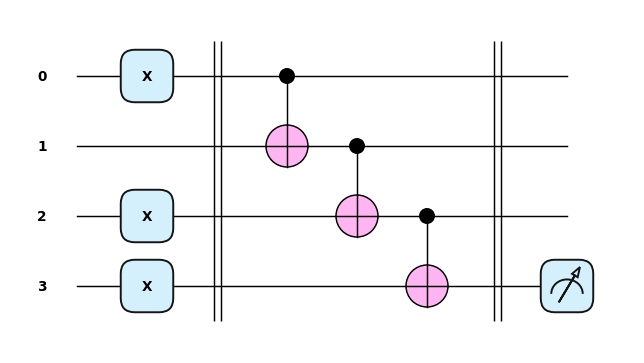

None


Single expectation value: -1.0



In [16]:
@qml.qnode(dev)
def basis_circuit_2B(features):
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    qml.Barrier()
    for i in range(len(features)-1):
        qml.CNOT([i, i+1])
    qml.Barrier()
    return qml.expval(qml.PauliZ(3)) # Only 1 value returned

X = [1, 0, 1, 1]

display(draw_circuit(basis_circuit_2B, level='user', scale=0.7)(X))
expvals = basis_circuit_2B(X)
print(f'\nSingle expectation value: {expvals}\n')

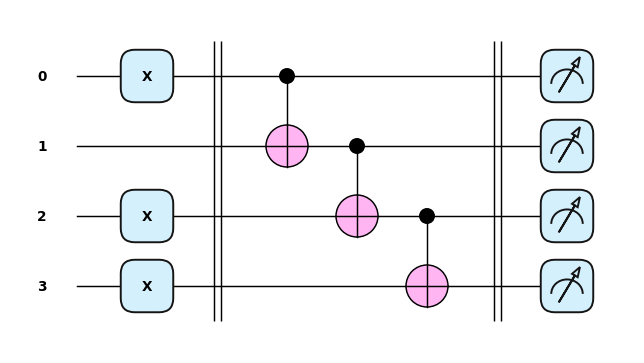

None


Tensor product value: -1.0



In [17]:
@qml.qnode(dev)
def basis_circuit_2C(features):
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    qml.Barrier()
    for i in range(len(features)-1):
        qml.CNOT([i, i+1])
    qml.Barrier()
    tensor_product = qml.prod(*(qml.PauliZ(i) for i in range(n_wires)))
    return qml.expval(tensor_product) # Only 1 value returned

X = [1, 0, 1, 1]

display(draw_circuit(basis_circuit_2C, level='user', scale=0.7)(X))
expvals = basis_circuit_2C(X)
print(f'\nTensor product value: {expvals}\n')

#### Measuring probabilities

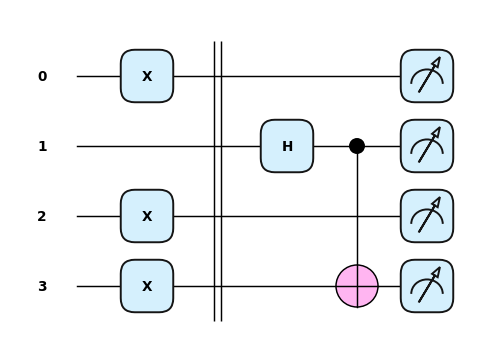

In [18]:
@qml.qnode(dev)
def basis_circuit_3(features):
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    qml.Barrier()
    qml.Hadamard(1)
    qml.CNOT([1, 3])
    return qml.probs(range(len(features)))

X = [1, 0, 1, 1]

draw_circuit(basis_circuit_3, level='user', scale=0.7)(X)


 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.5 0.  0.  0.5 0. ] 



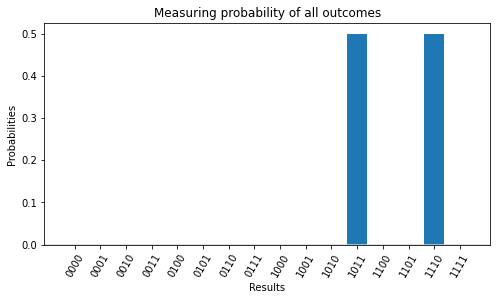

In [19]:
probs = basis_circuit_3(X)
print('\n', probs, '\n')
plot_hist(probs, figsize=(8, 4), ylabel='Probabilities', title='Measuring probability of all outcomes')

#### Spliting circuit observations into measured variables

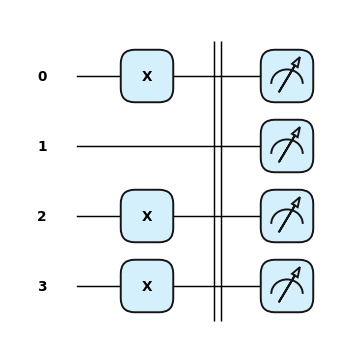

In [20]:
@qml.qnode(dev)
def basis_circuit_4(features):
    for i in range(len(features)):
        if features[i] == 1: qml.PauliX(i)
    qml.Barrier()
    return [qml.probs(range(len(features) // 2)), qml.probs(range(len(features) // 2, len(features)))]

X = [1, 0, 1, 1]

draw_circuit(basis_circuit_4, level='user', scale=0.7)(X)


 [array([0., 0., 1., 0.]), array([0., 0., 0., 1.])] 



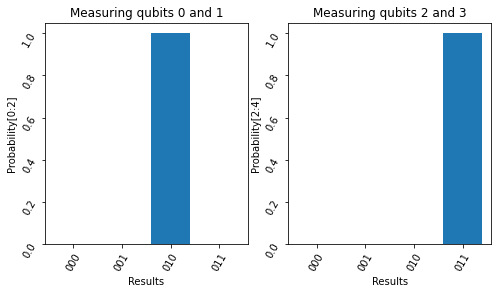

In [21]:
probs = basis_circuit_4(X)
print('\n', probs, '\n')
# plot_hist(probs[0], ylabel='Probabilities[0:2]')
# plot_hist(probs[1], ylabel='Probabilities[2:4]')

plot_compare_hist(probs[0], probs[1], figsize=(8, 4),
                      title_1='Measuring qubits 0 and 1', title_2='Measuring qubits 2 and 3',
                      xlabel_1='Results', xlabel_2='Results',
                      ylabel_1='Probability[0:2]', ylabel_2='Probability[2:4]')

### Angle embedding / encoding

#### Measuring probabilities

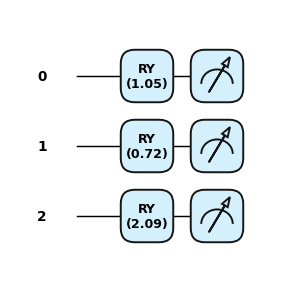

In [22]:
import numpy as np 

n_wires = 3
dev = qml.device('default.qubit', wires=n_wires)

@qml.qnode(dev)
def angle_circuit_1a(features):
    qml.AngleEmbedding(features=features, rotation='Y', wires=range(len(features)))
    return qml.probs(range(len(features)))

@qml.qnode(dev)
def angle_circuit_1b(features):
    qml.AngleEmbedding(features=features, rotation='Y', wires=range(len(features)))
    return [qml.probs(m) for m in range(len(features))]

X = [np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]

draw_circuit(angle_circuit_1a, level='device', scale=0.7)(X)


Input
Values entered:	[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]
Ry angles used:	[1.047, 0.723, 2.094]

Measurements
Probabilities:	[0.164, 0.492, 0.023, 0.07, 0.055, 0.164, 0.008, 0.023]



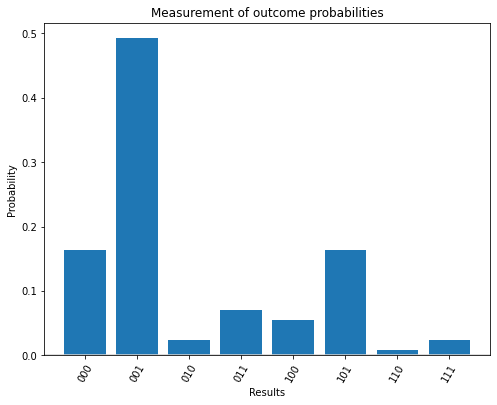

In [23]:
### Get the whole distribution of outcomes
dist_probs = np.array(angle_circuit_1a(X))

print('\nInput')
print(f'Values entered:\t[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]')
print(f'Ry angles used:\t{list(np.round(X, 3))}')
print('\nMeasurements')
print(f'Probabilities:\t{list(np.round(dist_probs, 3))}\n')

plot_hist(dist_probs, ylabel='Probability', title='Measurement of outcome probabilities')

In [24]:
print('\nOriginal probability distribution\n')
display(report_c2p(dist_probs, prec=3))
qprobs = cprobs_to_qprobs(dist_probs)
print(f'\nResult of mapping a circuit state to\nindividual qubit states:\n\n{np.round(qprobs, 3)}\n')


Original probability distribution



[([0, 0, 0], 0.164),
 ([0, 0, 1], 0.492),
 ([0, 1, 0], 0.023),
 ([0, 1, 1], 0.07),
 ([1, 0, 0], 0.055),
 ([1, 0, 1], 0.164),
 ([1, 1, 0], 0.008),
 ([1, 1, 1], 0.023)]


Result of mapping a circuit state to
individual qubit states:

[0.75  0.875 0.25 ]




Input
Values entered:	[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]
Ry angles used:	[1.047, 0.723, 2.094]

Measurements
Cond probs:	[[0.75, 0.25], [0.875, 0.125], [0.25, 0.75]]

Amplitudes:	[0.866, 0.935, 0.5]



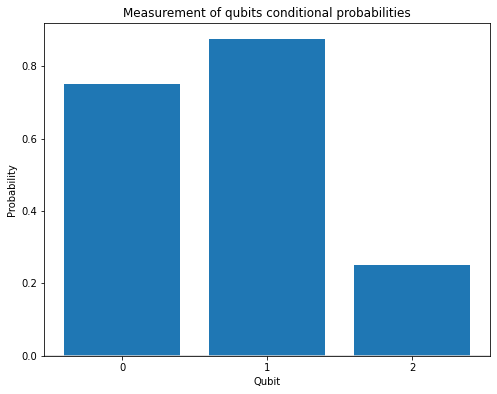

In [25]:
### Get conditional probabilities of each qubit P(0)
probs = np.array(angle_circuit_1b(X))

cond_probs = [ps[0] for ps in probs]
amps = np.sqrt([ps[0] for ps in probs])
print('\nInput')
print(f'Values entered:\t[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]')
print(f'Ry angles used:\t{list(np.round(X, 3))}')
print('\nMeasurements')
print(f'Cond probs:\t{[ list(e) for e in (np.round(probs, 5))]}\n')
print(f'Amplitudes:\t{list(np.round(amps, 3))}\n')
plot_hist(cond_probs, labels=['0', '1', '2'], xlabel='Qubit', ylabel='Probability', 
          title='Measurement of qubits conditional probabilities')

#### Measuring expectations

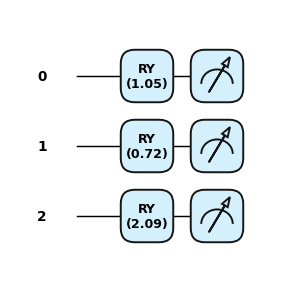

In [26]:
import numpy as np 

n_wires = 3
dev = qml.device('default.qubit', wires=n_wires)

@qml.qnode(dev)
def angle_circuit_2(features):
    qml.AngleEmbedding(features=features, rotation='Y', wires=range(len(features)))
    return [qml.expval(qml.PauliZ(m)) for m in range(len(features))]

X = [np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]

draw_circuit(angle_circuit_2, level='device', scale=0.7)(X)


Input
Values entered:	[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]
Ry angles used:	[1.047, 0.723, 2.094]

Measurements
Probabilities:	[[0.75, 0.25], [0.875, 0.125], [0.25, 0.75]]
Amplitudes:	[0.866, 0.935, 0.5]



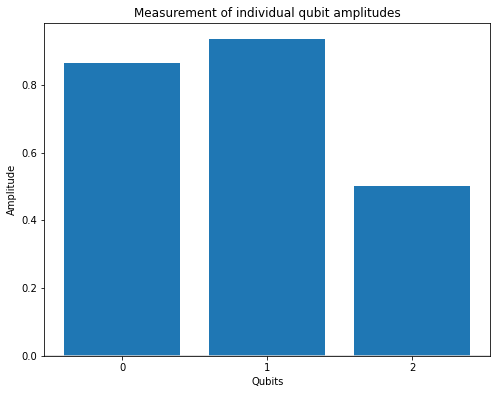

In [27]:
expvals = np.array(angle_circuit_2(X))
probs = [[(1 + epv) / 2, (1 - epv) / 2] for epv in expvals]
amps = np.sqrt([ps[0] for ps in probs])
print('\nInput')
print(f'Values entered:\t[np.arccos(0.5), np.arccos(0.75), np.pi-np.arccos(0.5)]')
print(f'Ry angles used:\t{list(np.round(X, 3))}')
print('\nMeasurements')
print(f'Probabilities:\t{[ list(p) for p in (np.round(probs, 3))]}')
print(f'Amplitudes:\t{list(np.round(amps, 3))}\n')
plot_hist(amps, xlabel='Qubits', ylabel='Amplitude', labels=['0', '1', '2'], 
          title='Measurement of individual qubit amplitudes')

## Modifications (do not remove)
Under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt) license, if you perform any changes to this notebook, please list them here, adding a note with your name, contact details, date and changes to the code.

- [Jacob Cybulski](http://jacobcybulski.com) (2024, 1 Oct): The author of this notebook added this section to record all code changes
- [Jacob Cybulski](http://jacobcybulski.com) (2026, 1 Oct): Now also compatible with...<br>
  pennylane                 0.45.0<br>
  pennylane_lightning       0.45.0<br>
  torch                     2.11.0+cpu<br>
  torchaudio                2.11.0<br>
  torchvision               0.26.0+cpu<br>

## Software (Linux)

In [28]:
import os
os.system('pip list | grep -e pennylane -e torch');